# Chapter 9: Text Processing and Multiclass Classification

## Comprehensive Summary
This chapter focuses on the techniques and methodologies for processing unstructured text data and transforming it into quantitative representations that machine learning algorithms can ingest. We explore tokenization, stop-word removal, and numerical vectorization paradigms, contrasting the Bag-of-Words (BoW) count representation with Term Frequency-Inverse Document Frequency (TF-IDF). Furthermore, we delve into capturing local linguistic structure via n-grams, constructing resilient text classification pipelines with Naive Bayes, Logistic Regression, and Support Vector Machines, and extending binary classifiers to multiclass domains using One-vs-Rest (OvR) and One-vs-One (OvO) reduction strategies.

## In-Depth Theoretical Analysis & Mechanism Breakdown

### 1. The Bag-of-Words (BoW) Model & Term Sparsity
Text data is inherently discrete, non-Euclidean, and sequence-dependent. The Bag-of-Words approach simplifies this by treating each document as an unordered collection of token occurrences:
* **Mechanism:** Given a vocabulary $V$ of unique terms across corpus $D$, a document $d$ is mapped to a vector $\mathbf{x} \in \mathbb{R}^{|V|}$ where $x_j$ represents the frequency count of term $t_j$ in document $d$.
* **Sparsity & Memory:** Because any individual document contains only a minuscule fraction of $|V|$, the resulting design matrix is overwhelmingly sparse ($>98\%$ zeros), requiring specialized compressed sparse row (`scipy.sparse.csr_matrix`) structures.

### 2. Term Frequency-Inverse Document Frequency (TF-IDF)
Raw word counts disproportionately reward high-frequency function words ("the", "is", "at") over discriminative content terms. TF-IDF corrects for this via inverse document weighting:
$$\text{tf-idf}(t, d, D) = \text{tf}(t, d) \times \text{idf}(t, D)$$
In scikit-learn, the smooth IDF formulation is used:
$$\text{idf}(t, D) = \ln\left(\frac{1 + |D|}{1 + |\{d \in D : t \in d\}|}\right) + 1$$
Following computation, vectors are Euclidean $L_2$-normalized:
$$\mathbf{v}_{\text{norm}} = \frac{\mathbf{v}}{\|\mathbf{v}\|_2}$$
This bounds vector lengths to unit hyperspheres, neutralizing document length discrepancies.

### 3. Preserving Contextual Order via N-grams
While pure unigrams discard syntax and word order, extending feature extraction to n-tuples of consecutive tokens (bigrams, trigrams) captures critical local dependencies (e.g., distinguishing "not good" from "good"):
* **Trade-off:** N-gram vocabularies grow combinatorially with $n$. Pruning parameters (`min_df`, `max_df`, `max_features`) become essential to prevent catastrophic dimensionality explosion and severe overfitting.

### 4. Multiclass Reduction Strategies
When moving beyond binary classification to $K > 2$ discrete classes:
* **One-vs-Rest (OvR / One-vs-All):** Trains $K$ independent binary classifiers, each separating class $k$ from all remaining $K-1$ classes. Computationally linear in $K$ ($O(K)$), but susceptible to class imbalance in base classifiers.
* **One-vs-One (OvO):** Trains $\frac{K(K-1)}{2}$ binary classifiers for every pairwise combination of classes. Prediction is decided by majority voting. More computationally demanding for large $K$, but each individual classifier trains on a balanced sub-problem.
* **Multinomial Logistic Regression:** Minimizes Cross-Entropy Loss directly over the softmax probability distribution:
$$P(y = k \mid \mathbf{x}) = \frac{e^{\mathbf{w}_k^T \mathbf{x} + b_k}}{\sum_{j=1}^K e^{\mathbf{w}_j^T \mathbf{x} + b_j}}$$

### 5. Classification Algorithms for Sparse NLP
* **Multinomial Naive Bayes (`MultinomialNB`):** Assumes conditional feature independence given class label. Extremely fast $O(|V|)$ fitting with Laplace smoothing ($\alpha = 1.0$), highly resilient to small sample sizes.
* **Linear Support Vector Classifier (`LinearSVC`):** Finds the maximum-margin hyperplane in high-dimensional sparse feature spaces using LibLinear. Proven standard for large-scale text classification.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set aesthetic styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
print("Environment and libraries initialized successfully.")

Environment and libraries initialized successfully.


In [2]:
import nltk
from nltk.corpus import movie_reviews

# Load movie reviews dataset
documents = [
    (" ".join(movie_reviews.words(fileid)), category)
    for category in movie_reviews.categories()
    for fileid in movie_reviews.fileids(category)
]

df_reviews = pd.DataFrame(documents, columns=['text', 'sentiment'])
print(f"Total documents loaded: {len(df_reviews)}")
print(f"Class distribution:\n{df_reviews['sentiment'].value_counts()}\n")
print("Sample review excerpt (first 250 characters):")
print(f"'{df_reviews['text'].iloc[0][:250]}...'")

Total documents loaded: 2000
Class distribution:
sentiment
neg    1000
pos    1000
Name: count, dtype: int64

Sample review excerpt (first 250 characters):
'plot : two teen couples go to a church party , drink and then drive . they get into an accident . one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . what ' s the deal ? watch the movie and " sorta " find...'


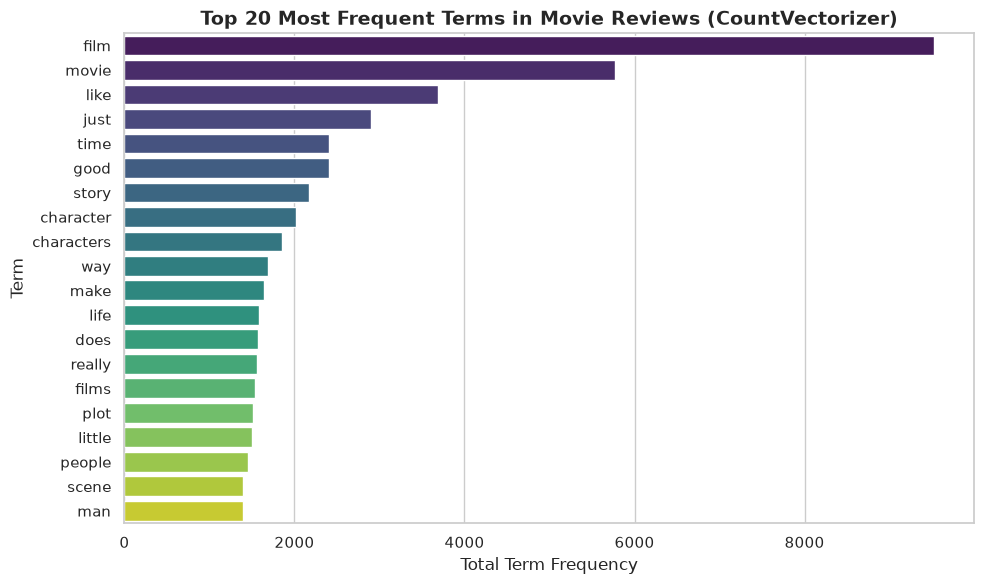

In [3]:
from sklearn.feature_extraction.text import CountVectorizer

# Instantiate CountVectorizer with English stop-words removal
bow_vectorizer = CountVectorizer(stop_words='english', max_features=5000)
X_bow = bow_vectorizer.fit_transform(df_reviews['text'])

# Compute total word frequency across the entire corpus
term_frequencies = np.asarray(X_bow.sum(axis=0)).flatten()
feature_names = np.array(bow_vectorizer.get_feature_names_out())

# Extract top 20 most frequent terms
top_indices = np.argsort(term_frequencies)[::-1][:20]
df_top_terms = pd.DataFrame({
    'term': feature_names[top_indices],
    'frequency': term_frequencies[top_indices]
})

# Visualize top 20 frequent terms
plt.figure(figsize=(10, 6))
sns.barplot(data=df_top_terms, x='frequency', y='term', palette='viridis')
plt.title("Top 20 Most Frequent Terms in Movie Reviews (CountVectorizer)", fontsize=14, fontweight='bold')
plt.xlabel("Total Term Frequency")
plt.ylabel("Term")
plt.tight_layout()
plt.show()

BoW Matrix shape: (2000, 5000), Non-zero elements: 370854
TF-IDF Matrix shape: (2000, 5000), Sparsity: 96.29%


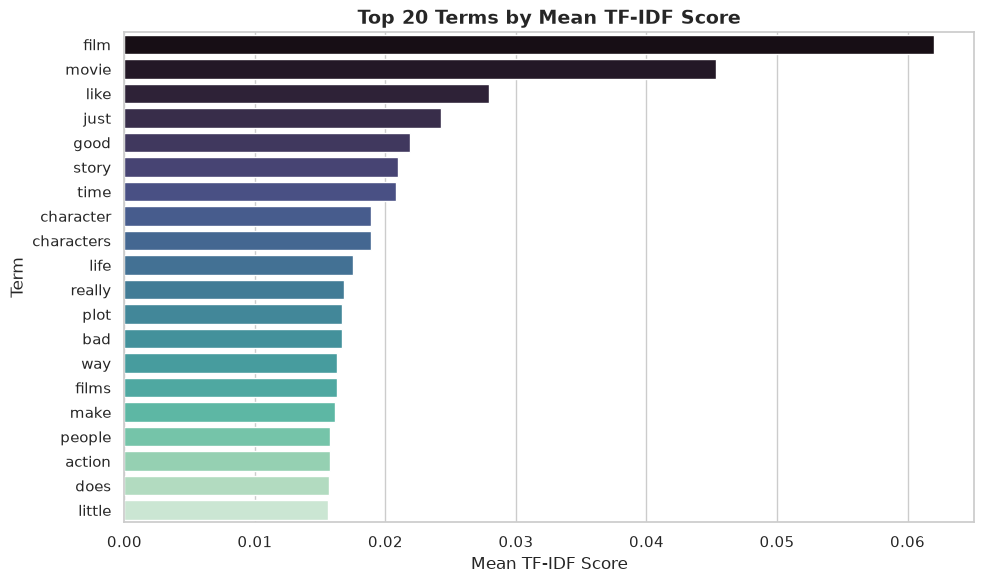

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Compare CountVectorizer vs TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer(stop_words='english', max_features=5000)
X_tfidf = tfidf_vectorizer.fit_transform(df_reviews['text'])

# Calculate average TF-IDF score for each term
avg_tfidf_scores = np.asarray(X_tfidf.mean(axis=0)).flatten()
top_tfidf_indices = np.argsort(avg_tfidf_scores)[::-1][:20]

df_top_tfidf = pd.DataFrame({
    'term': feature_names[top_tfidf_indices],
    'mean_tfidf': avg_tfidf_scores[top_tfidf_indices]
})

plt.figure(figsize=(10, 6))
sns.barplot(data=df_top_tfidf, x='mean_tfidf', y='term', palette='mako')
plt.title("Top 20 Terms by Mean TF-IDF Score", fontsize=14, fontweight='bold')
plt.xlabel("Mean TF-IDF Score")
plt.ylabel("Term")
plt.tight_layout()
plt.show()

print(f"BoW Matrix shape: {X_bow.shape}, Non-zero elements: {X_bow.nnz}")
print(f"TF-IDF Matrix shape: {X_tfidf.shape}, Sparsity: {100 * (1 - X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1])):.2f}%")

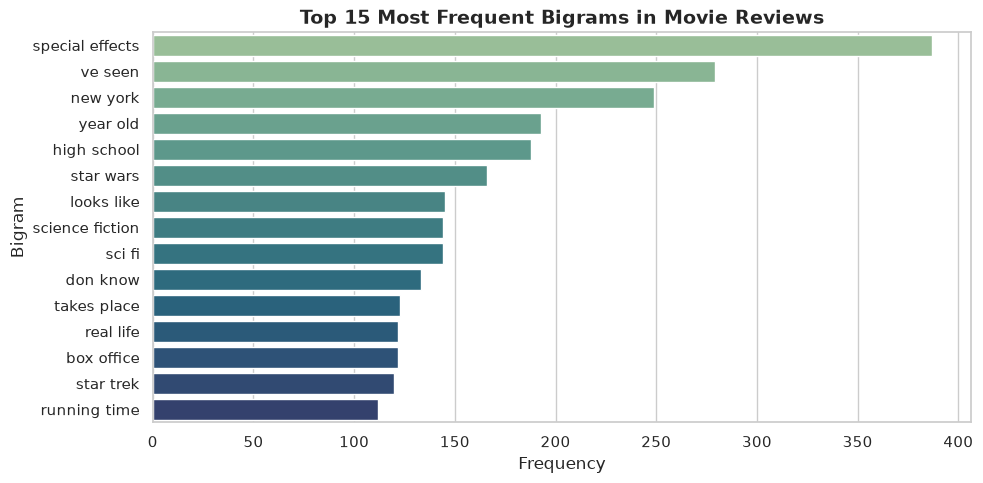

In [5]:
# Feature extraction with n-grams (Unigrams vs Bigrams)
ngram_vectorizer = CountVectorizer(ngram_range=(1, 2), stop_words='english', min_df=5, max_features=5000)
X_ngram = ngram_vectorizer.fit_transform(df_reviews['text'])
ngram_names = ngram_vectorizer.get_feature_names_out()

# Filter out bigrams specifically
bigrams = [term for term in ngram_names if ' ' in term]
bigram_counts = np.asarray(X_ngram[:, [ngram_vectorizer.vocabulary_[bg] for bg in bigrams]].sum(axis=0)).flatten()

top_bg_idx = np.argsort(bigram_counts)[::-1][:15]
df_top_bigrams = pd.DataFrame({
    'bigram': [bigrams[i] for i in top_bg_idx],
    'frequency': bigram_counts[top_bg_idx]
})

plt.figure(figsize=(10, 5))
sns.barplot(data=df_top_bigrams, x='frequency', y='bigram', palette='crest')
plt.title("Top 15 Most Frequent Bigrams in Movie Reviews", fontsize=14, fontweight='bold')
plt.xlabel("Frequency")
plt.ylabel("Bigram")
plt.tight_layout()
plt.show()

Binary Text Classification Benchmark:
                  Model  Accuracy  F1-Score
Multinomial Naive Bayes     0.812  0.808163
    Logistic Regression     0.814  0.817289
             Linear SVC     0.836  0.837302


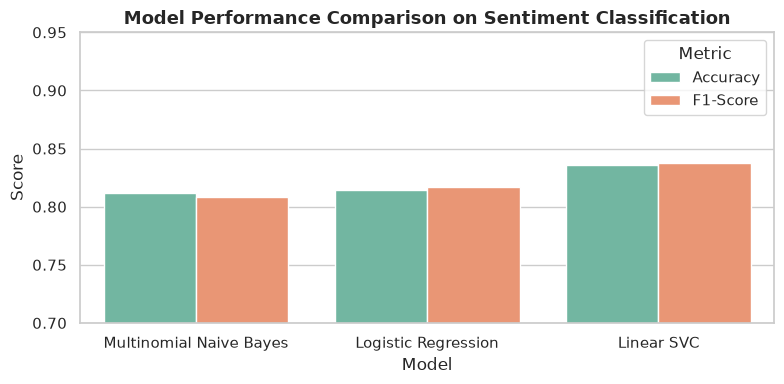

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Split data: 75% train, 25% test
X_train, X_test, y_train, y_test = train_test_split(
    df_reviews['text'], df_reviews['sentiment'],
    test_size=0.25, random_state=2024, stratify=df_reviews['sentiment']
)

# Benchmark multiple classification architectures inside Pipelines
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=1.0),
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=2024),
    "Linear SVC": LinearSVC(C=1.0, random_state=2024)
}

results = []
for name, clf in models.items():
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', ngram_range=(1, 2), max_features=10000)),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, pos_label='pos')
    results.append({'Model': name, 'Accuracy': acc, 'F1-Score': f1})

df_results = pd.DataFrame(results)
print("Binary Text Classification Benchmark:")
print(df_results.to_string(index=False))

# Visualization of Model Comparison
plt.figure(figsize=(8, 4))
df_melted = df_results.melt(id_vars='Model', value_vars=['Accuracy', 'F1-Score'], var_name='Metric', value_name='Score')
sns.barplot(data=df_melted, x='Model', y='Score', hue='Metric', palette='Set2')
plt.ylim(0.7, 0.95)
plt.title("Model Performance Comparison on Sentiment Classification", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [7]:
from nltk.corpus import brown
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier

# Load multi-category text data from NLTK Brown corpus
selected_categories = ['news', 'editorial', 'reviews', 'religion', 'government']
brown_docs = []
for cat in selected_categories:
    for fileid in brown.fileids(categories=cat):
        brown_docs.append((" ".join(brown.words(fileid)), cat))

df_brown = pd.DataFrame(brown_docs, columns=['text', 'category'])
print(f"Loaded Brown Corpus subsets: {len(df_brown)} documents across {len(selected_categories)} classes.")
print(df_brown['category'].value_counts())

# Split into train and test sets
X_b_train, X_b_test, y_b_train, y_b_test = train_test_split(
    df_brown['text'], df_brown['category'],
    test_size=0.3, random_state=2024, stratify=df_brown['category']
)

# Text vectorizer
b_vectorizer = TfidfVectorizer(stop_words='english', max_features=5000)
X_b_train_vect = b_vectorizer.fit_transform(X_b_train)
X_b_test_vect = b_vectorizer.transform(X_b_test)

# Compare Multiclass Strategies
mc_strategies = {
    "Direct Softmax Logistic Regression": LogisticRegression(max_iter=1000, random_state=2024),
    "One-vs-Rest (OvR)": OneVsRestClassifier(LogisticRegression(max_iter=1000, random_state=2024)),
    "One-vs-One (OvO)": OneVsOneClassifier(LogisticRegression(max_iter=1000, random_state=2024))
}

mc_results = []
for strat_name, model in mc_strategies.items():
    model.fit(X_b_train_vect, y_b_train)
    preds = model.predict(X_b_test_vect)
    acc = accuracy_score(y_b_test, preds)
    macro_f1 = f1_score(y_b_test, preds, average='macro')
    mc_results.append({'Strategy': strat_name, 'Accuracy': acc, 'Macro F1': macro_f1})

df_mc = pd.DataFrame(mc_results)
print("\nMulticlass Classification Performance across Strategies:")
print(df_mc.to_string(index=False))

Loaded Brown Corpus subsets: 135 documents across 5 classes.
category
news          44
government    30
editorial     27
reviews       17
religion      17
Name: count, dtype: int64

Multiclass Classification Performance across Strategies:
                          Strategy  Accuracy  Macro F1
Direct Softmax Logistic Regression  0.487805  0.378149
                 One-vs-Rest (OvR)  0.414634  0.209804
                  One-vs-One (OvO)  0.365854  0.143704


Comprehensive Classification Report:
              precision    recall  f1-score   support

        news       0.00      0.00      0.00         8
   editorial       1.00      0.44      0.62         9
     reviews       0.44      1.00      0.61        14
    religion       1.00      0.20      0.33         5
  government       1.00      0.20      0.33         5

    accuracy                           0.49        41
   macro avg       0.69      0.37      0.38        41
weighted avg       0.61      0.49      0.42        41



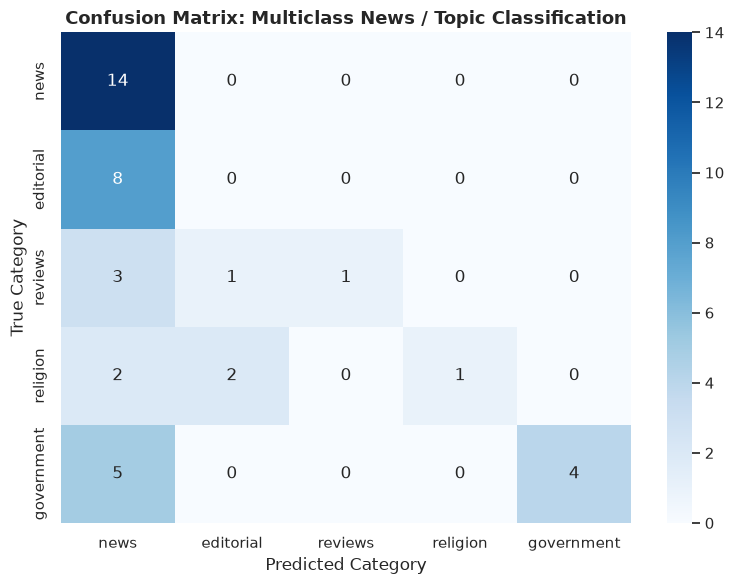

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Evaluate best multiclass model
best_mc_model = mc_strategies["Direct Softmax Logistic Regression"]
y_pred_best = best_mc_model.predict(X_b_test_vect)

print("Comprehensive Classification Report:")
print(classification_report(y_b_test, y_pred_best, target_names=selected_categories))

# Plot Confusion Matrix
cm = confusion_matrix(y_b_test, y_pred_best, labels=selected_categories)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=selected_categories, yticklabels=selected_categories)
plt.title("Confusion Matrix: Multiclass News / Topic Classification", fontsize=13, fontweight='bold')
plt.xlabel("Predicted Category")
plt.ylabel("True Category")
plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import GridSearchCV

# Exercise 1 & 2: Feature Extraction with Character vs Word N-Grams
sample_texts = [
    "Machine learning transforms automated intelligence and natural language processing.",
    "Deep neural networks require substantial computational GPUs and high quality labeled training data.",
    "Statistical learning theory establishes finite sample bounds and regularization convergence."
]

char_vect = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 4))
X_char = char_vect.fit_transform(sample_texts)
print(f"Character n-gram vocabulary size: {len(char_vect.get_feature_names_out())}")
print(f"Sample char n-grams: {list(char_vect.get_feature_names_out())[:10]}")

# Exercise 3: Complete Hyperparameter Grid Search over NLP Pipeline
pipeline_cv = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=3000)),
    ('clf', LogisticRegression(random_state=2024, max_iter=500))
])

param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'clf__C': [0.1, 1.0, 10.0]
}

grid_nlp = GridSearchCV(pipeline_cv, param_grid, cv=3, scoring='accuracy', n_jobs=1)
grid_nlp.fit(X_train, y_train)

print(f"Best GridSearch CV Score: {grid_nlp.best_score_:.4f}")
print("Optimal Hyperparameters:")
for param, val in grid_nlp.best_params_.items():
    print(f" - {param}: {val}")

final_acc = grid_nlp.score(X_test, y_test)
print(f"Final Tuned Test Accuracy: {final_acc:.4f}")

Character n-gram vocabulary size: 395
Sample char n-grams: [' an', ' and', ' au', ' aut', ' bo', ' bou', ' co', ' com', ' con', ' da']
Best GridSearch CV Score: 0.8207
Optimal Hyperparameters:
 - clf__C: 10.0
 - tfidf__ngram_range: (1, 2)
Final Tuned Test Accuracy: 0.8280
